# Predicting Residential Construction Costs Using Machine Learning

### A Time-Aware and Explainable Machine Learning Study

**Author:** Yasaman Sharif

## Project Overview

This project investigates whether machine learning can predict residential construction costs using project characteristics and information available at the beginning of construction.

Rather than focusing only on achieving a high prediction score, the analysis evaluates how well models generalize to future projects. Particular attention is given to data leakage, categorical feature encoding, temporal validation, model interpretability, and robustness.

The project compares Linear Regression, Random Forest, and Gradient Boosting models using both random cross-validation and a strict future holdout evaluation.


## Research Question

**Can information available at the beginning of a residential construction project be used to predict its future construction cost?**

A secondary objective is to investigate which project characteristics contribute most strongly to future cost prediction and how model performance changes when predicting projects from later time periods.


## Dataset

The analysis uses the Residential Building dataset from the UCI Machine Learning Repository.

The dataset contains 372 residential construction projects and includes:

- project characteristics such as total floor area, lot area, project locality, and construction timing
- economic and market indicators
- preliminary construction cost estimates
- actual sales prices
- actual construction costs

The target variable in this study is **Actual Construction Cost (V-10)**.

To make the analysis suitable for real-world forecasting, particular attention is given to distinguishing between information available at the beginning of a project and information that becomes available later.

## Data Preparation

The raw Excel dataset contains duplicated variable names and multiple time-lagged economic variables.

The main preparation steps included:

1. Reading and restructuring the original Excel file.
2. Renaming the output variables for clarity.
3. Checking for missing values and duplicate records.
4. Separating the prediction target from the input features.
5. Identifying variables that could cause data leakage.
6. Treating project locality and start quarter as categorical variables.
7. Applying one-hot encoding to categorical variables.
8. Creating a strict time-based train/test split to evaluate performance on future projects.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os

# File paths
zip_path = '/residential+building+data+set.zip'
extract_path = '/content/residential_data'

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

file_path = os.path.join(
    extract_path,
    'Residential-Building-Data-Set.xlsx'
)

# Load main data
df = pd.read_excel(
    file_path,
    sheet_name='Data',
    header=1
)

# Remove empty rows
df = df.dropna(how='all')

# Rename output variables
df = df.rename(columns={
    'V-9': 'Actual_Sales_Price',
    'V-10': 'Actual_Construction_Cost'
})

# Load variable descriptions
desc = pd.read_excel(
    file_path,
    sheet_name='Descriptions',
    header=0
)

desc.columns = desc.columns.astype(str).str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (372, 109)


,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,...,V-22.4,V-23.4,V-24.4,V-25.4,V-26.4,V-27.4,V-28.4,V-29.4,Actual_Sales_Price,Actual_Construction_Cost
0,81,1,85,1,1,3150.0,920.0,598.5,190,1010.84,...,815.50,1755.00,8002.0,60.74,54.26,2978.26,41407.0,601988.1,2200,410
1,84,1,89,4,1,7600.0,1140.0,3040.0,400,963.81,...,1316.30,8364.78,8393.0,90.95,89.79,11379.37,44835.0,929027.1,5000,1000
2,78,1,81,4,1,4800.0,840.0,480.0,100,689.84,...,765.80,1755.00,4930.0,38.70,32.04,1653.06,37933.0,377828.6,1200,170
3,72,2,73,2,1,685.0,202.0,13.7,20,459.54,...,152.25,1442.31,1456.0,9.73,8.34,686.16,8194.0,122031.7,165,30
4,87,1,90,2,1,3000.0,800.0,1230.0,410,631.91,...,2244.10,9231.76,9286.0,136.60,140.20,9821.00,48260.0,1734973.5,5500,700


## Data Quality and Exploratory Analysis

Before developing prediction models, the dataset was examined for data quality issues and the distribution of the target variable.

The analysis focused on:

- dataset dimensions
- missing values
- duplicate observations
- summary statistics of the target variable
- the distribution of actual construction costs

Understanding the target distribution is particularly important because large differences between low-cost and high-cost projects may affect model performance.

Dataset dimensions:
Rows: 372
Columns: 109

Total missing values:
0

Duplicate rows:
0

Target summary:


,Actual_Construction_Cost
count,372.000000
mean,232.647849
std,162.627656
min,20.000000
25%,110.000000
50%,190.000000
75%,330.000000
max,1000.000000


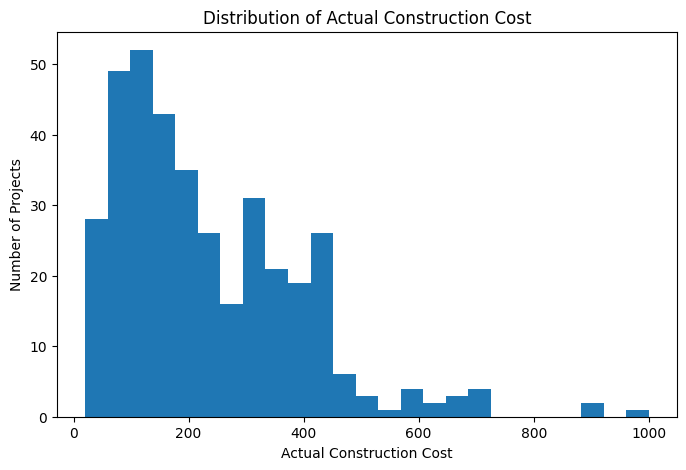

In [ ]:
# Data quality checks

print("Dataset dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nTotal missing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget summary:")
display(
    df['Actual_Construction_Cost']
    .describe()
    .to_frame()
)

# Target distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df['Actual_Construction_Cost'],
    bins=25
)

plt.xlabel('Actual Construction Cost')
plt.ylabel('Number of Projects')
plt.title('Distribution of Actual Construction Cost')

plt.show()

## Feature Selection and Data Leakage Prevention

To simulate a realistic forecasting scenario, only variables that could reasonably be available at the beginning of a construction project were selected.

Variables containing future information or direct preliminary cost estimates were excluded to reduce the risk of data leakage.

The final predictor set includes:

- Start year
- Start quarter
- Project locality
- Total floor area
- Lot area
- Unit price at the beginning of the project
- Average market construction cost at the beginning of construction

The prediction target is **Actual Construction Cost**.

A strict time-based holdout is used later in the analysis so that models are trained on earlier projects and evaluated on projects from later years.

In [ ]:
# Define the final start-time feature set

start_features = [
    'START YEAR',
    'START QUARTER',
    'V-1',   # Project locality
    'V-2',   # Total floor area
    'V-3',   # Lot area
    'V-8',   # Unit price at project start
    'V-22'   # Market construction cost at start
]

target = 'Actual_Construction_Cost'

X = df[start_features].copy()
y = df[target].copy()

print("Selected features:")
for feature in start_features:
    print("-", feature)

print("\nNumber of predictors:", X.shape[1])
print("Number of projects:", X.shape[0])

Selected features:
- START YEAR
- START QUARTER
- V-1
- V-2
- V-3
- V-8
- V-22

Number of predictors: 7
Number of projects: 372


## Categorical Encoding and Time-Based Validation

Project locality and start quarter are categorical variables and should not be treated as continuous numerical values.

To represent them correctly, one-hot encoding is applied within a preprocessing pipeline.

For a realistic evaluation, the dataset is also divided chronologically:

- Projects starting in year 86 or earlier are used for training.
- Projects starting after year 86 are reserved as a strict future holdout set.

This setup evaluates whether the models can generalize to projects from later time periods rather than simply predicting randomly selected projects from the same historical distribution.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Categorical and numerical variables
categorical_features = [
    'V-1',
    'START QUARTER'
]

numeric_features = [
    'START YEAR',
    'V-2',
    'V-3',
    'V-8',
    'V-22'
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'num',
            StandardScaler(),
            numeric_features
        )
    ]
)

# Strict future holdout
train_mask = df['START YEAR'] <= 86
test_mask = df['START YEAR'] > 86

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training projects:", len(X_train))
print("Future test projects:", len(X_test))

print(
    "Training years:",
    X_train['START YEAR'].min(),
    "to",
    X_train['START YEAR'].max()
)

print(
    "Testing years:",
    X_test['START YEAR'].min(),
    "to",
    X_test['START YEAR'].max()
)

Training projects: 334
Future test projects: 38
Training years: 72 to 86
Testing years: 87 to 88


## Model Development and Comparison

Three regression approaches were evaluated:

- Linear Regression
- Random Forest
- Gradient Boosting

A simple mean-based baseline model was also included for comparison.

All models were trained exclusively on projects from earlier years and evaluated on the strict future holdout set. Performance was measured using:

- **MAE (Mean Absolute Error):** average absolute prediction error
- **RMSE (Root Mean Squared Error):** gives greater weight to large prediction errors
- **R²:** proportion of variation in construction costs explained by the model

Lower MAE and RMSE values indicate better performance, while higher R² values indicate stronger predictive ability.

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define models
models = {
    'Baseline (Mean)': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', DummyRegressor(strategy='mean'))
    ]),

    'Linear Regression': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', LinearRegression())
    ]),

    'Random Forest': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    'Gradient Boosting': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=2,
            random_state=42
        ))
    ])
}

results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    predictions[name] = pred

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        'R2',
        ascending=False
    )
)

,Model,MAE,RMSE,R2
2,Random Forest,78.927895,105.879366,0.478665
3,Gradient Boosting,74.997743,107.828912,0.459289
1,Linear Regression,90.624239,108.448160,0.453061
0,Baseline (Mean),235.632682,277.535736,-2.582055


## Cross-Validation on Historical Training Data

The strict future holdout set was kept completely separate from model development.

To assess model stability before evaluating future projects, five-fold cross-validation was performed only on the historical training data.

This prevents information from the future holdout period from influencing model selection and provides a more reliable estimate of how consistently each model performs across different subsets of the historical data.

In [ ]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    if name == 'Baseline (Mean)':
        continue

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'mse': 'neg_mean_squared_error',
            'r2': 'r2'
        }
    )

    mae = -scores['test_mae']
    rmse = np.sqrt(-scores['test_mse'])
    r2 = scores['test_r2']

    cv_results.append({
        'Model': name,
        'CV MAE': mae.mean(),
        'CV RMSE': rmse.mean(),
        'CV R2': r2.mean(),
        'R2 Std': r2.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        'CV R2',
        ascending=False
    )
)

,Model,CV MAE,CV RMSE,CV R2,R2 Std
1,Random Forest,44.552746,71.730362,0.751826,0.121726
0,Linear Regression,46.967979,72.738902,0.747270,0.139865
2,Gradient Boosting,45.992216,74.387757,0.735676,0.120073


## Final Model Selection

Random Forest was selected as the final model because it achieved the strongest overall performance across both validation strategies.

On the historical training data, five-fold cross-validation produced a mean R² of approximately **0.75**. On the strict future holdout set, the model achieved an R² of approximately **0.48**.

The lower performance on future projects highlights an important limitation: predicting construction costs becomes substantially more difficult when market conditions shift over time.

This difference between random cross-validation and future-period validation is therefore treated as an important finding rather than simply a reduction in model performance.

In [ ]:
# Select and fit the final Random Forest model

final_model = models['Random Forest']

final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("Final Random Forest Model")
print("-------------------------")
print(f"MAE  : {final_mae:.2f}")
print(f"RMSE : {final_rmse:.2f}")
print(f"R²   : {final_r2:.3f}")

Final Random Forest Model
-------------------------
MAE  : 78.93
RMSE : 105.88
R²   : 0.479


## Model Explainability

To understand which input variables contribute most to the final model's predictions, permutation feature importance was calculated on the future holdout set.

Permutation importance measures how much model performance decreases when the values of one feature are randomly shuffled.

A larger importance value indicates that the model relies more heavily on that feature when predicting construction costs.

In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance on the strict future holdout set
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values(
    'Importance',
    ascending=False
)

display(importance_df)

,Feature,Importance,Std
5,V-8,0.746879,0.206416
2,V-1,0.216828,0.107650
3,V-2,0.026113,0.051263
6,V-22,0.000000,0.000000
0,START YEAR,0.000000,0.000000
1,START QUARTER,-0.011053,0.006750
4,V-3,-0.018822,0.013119


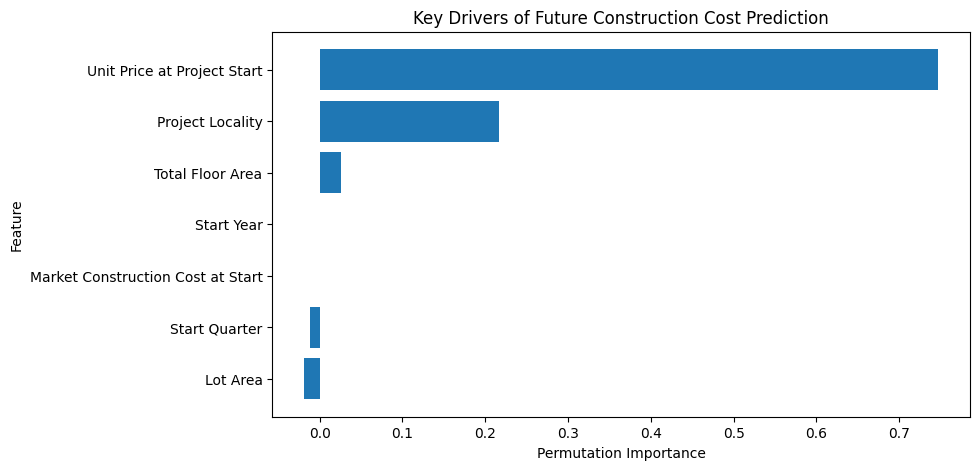

In [ ]:
feature_names = {
    'V-1': 'Project Locality',
    'V-2': 'Total Floor Area',
    'V-3': 'Lot Area',
    'V-8': 'Unit Price at Project Start',
    'V-22': 'Market Construction Cost at Start',
    'START YEAR': 'Start Year',
    'START QUARTER': 'Start Quarter'
}

plot_df = importance_df.copy()

plot_df['Feature Label'] = (
    plot_df['Feature']
    .map(feature_names)
    .fillna(plot_df['Feature'])
)

plot_df = plot_df.sort_values('Importance')

plt.figure(figsize=(9, 5))

plt.barh(
    plot_df['Feature Label'],
    plot_df['Importance']
)

plt.xlabel('Permutation Importance')
plt.ylabel('Feature')
plt.title('Key Drivers of Future Construction Cost Prediction')

plt.show()

## Robustness Test

Permutation importance identified the unit price at the beginning of the project as the most influential predictor.

To test whether the model depends excessively on this single variable, a robustness analysis was performed by removing this feature and retraining the Random Forest model.

If predictive performance decreases substantially, this provides evidence that the variable contains important information. If the model still retains meaningful predictive ability, other project characteristics also contribute independently to construction cost prediction.

In [ ]:
# Robustness test: remove the most important feature (V-8)

features_without_v8 = [
    'START YEAR',
    'START QUARTER',
    'V-1',
    'V-2',
    'V-3',
    'V-22'
]

X_no_v8 = df[features_without_v8].copy()

X_no_v8_train = X_no_v8.loc[train_mask]
X_no_v8_test = X_no_v8.loc[test_mask]

categorical_no_v8 = [
    'V-1',
    'START QUARTER'
]

numeric_no_v8 = [
    'START YEAR',
    'V-2',
    'V-3',
    'V-22'
]

preprocessor_no_v8 = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_no_v8
        ),
        (
            'num',
            StandardScaler(),
            numeric_no_v8
        )
    ]
)

rf_no_v8 = Pipeline([
    ('preprocess', preprocessor_no_v8),
    ('model', RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ))
])

rf_no_v8.fit(X_no_v8_train, y_train)

pred_no_v8 = rf_no_v8.predict(X_no_v8_test)

print("Random Forest without Unit Price at Project Start")
print("-------------------------------------------------")
print(f"MAE  : {mean_absolute_error(y_test, pred_no_v8):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred_no_v8)):.2f}")
print(f"R²   : {r2_score(y_test, pred_no_v8):.3f}")

Random Forest without Unit Price at Project Start
-------------------------------------------------
MAE  : 85.74
RMSE : 118.86
R²   : 0.343


### Robustness Test Result

Removing the unit price at the beginning of the project reduced the future-holdout R² from **0.479 to 0.343**.

This confirms that the variable provides substantial predictive information. However, the model still retained meaningful predictive ability without it, indicating that other project characteristics such as locality and physical project features also contribute independently to construction cost prediction.

## Prediction Performance

The final Random Forest model was evaluated by comparing predicted construction costs with actual costs for projects in the strict future holdout period.

Points closer to the diagonal reference line represent more accurate predictions.

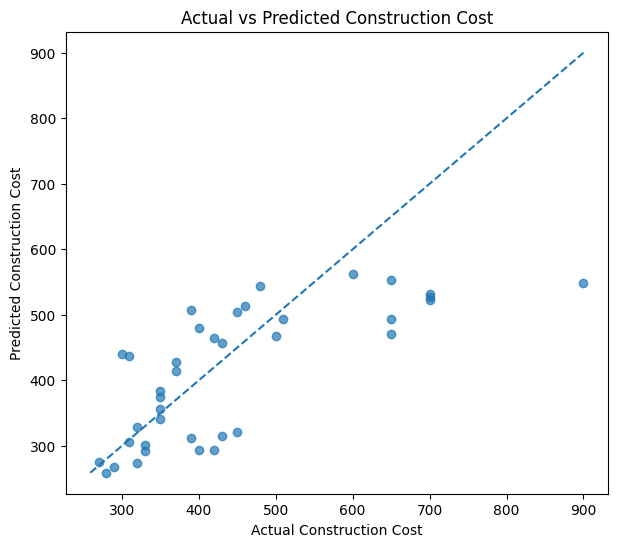

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Construction Cost')
plt.ylabel('Predicted Construction Cost')
plt.title('Actual vs Predicted Construction Cost')

plt.show()

## Residual Analysis

Residuals were examined to identify systematic prediction errors.

Residuals are calculated as:

**Actual Cost − Predicted Cost**

Positive residuals indicate underprediction, while negative residuals indicate overprediction. Ideally, residuals should be distributed around zero without a clear systematic pattern.

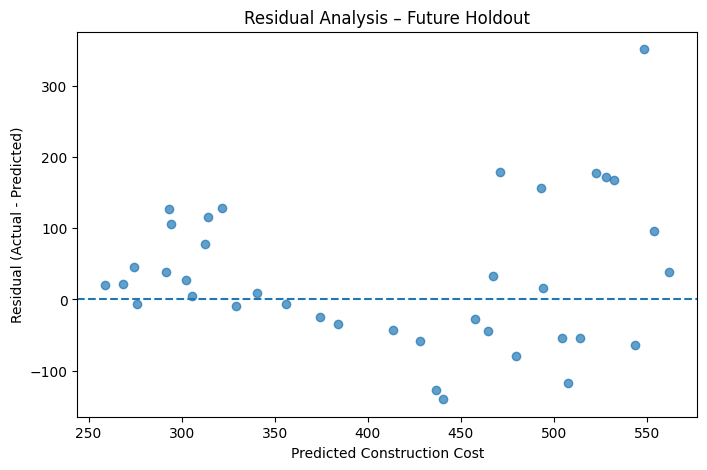

In [ ]:
residuals = y_test.values - final_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    final_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Construction Cost')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Analysis – Future Holdout')

plt.show()

## Limitations

Several limitations should be considered when interpreting the results of this study.

1. The dataset contains only 372 residential projects, which limits the amount of information available for training more complex machine-learning models.

2. Construction costs changed substantially across time periods. Although a strict future holdout was used, this temporal shift made forecasting later projects considerably more difficult.

3. The model relies strongly on the unit price at the beginning of the project. The robustness test showed that removing this variable reduced future-holdout R² from approximately **0.48 to 0.34**.

4. Residual analysis indicates that prediction errors are not perfectly uniform. In particular, some high-cost projects are substantially underestimated.

5. The dataset represents residential construction projects from a specific geographic and economic context. Therefore, the model should not be assumed to generalize directly to other cities, countries, or construction markets without further validation.

6. The model is intended as a predictive decision-support tool rather than a replacement for professional cost estimation.

## Conclusion

This project investigated whether residential construction costs can be predicted using machine-learning models and information available at the beginning of a project.

Among the evaluated models, **Random Forest showed the strongest overall performance across the evaluation settings**. On historical training data, five-fold cross-validation produced a mean R² of approximately **0.75**. When evaluated on a strict future holdout set, performance decreased to approximately **0.48**, demonstrating that forecasting construction costs across changing market conditions is substantially more difficult than predicting randomly selected historical projects.

Permutation importance identified the **unit price at the beginning of the project** and **project locality** as the most influential predictors. A robustness test confirmed the importance of the unit-price variable while also showing that other project characteristics retained independent predictive value.

The study highlights the importance of data leakage prevention, correct treatment of categorical variables, temporal validation, model interpretability, and robustness testing when developing machine-learning models for real-world construction forecasting.

Overall, the results suggest that machine learning can provide useful support for early-stage construction cost forecasting, while also emphasizing the limitations created by changing market conditions and limited historical data.